# Corrective Retrieval-Augmented Generation (CRAG) with LangGraph

This notebook implements a complete, end-to-end **Corrective RAG (CRAG)** pipeline using **LangGraph**, **Groq**, **Chroma DB**, and **Tavily Search**.

### CRAG Workflow Summary:
1. **Retrieve**: Retrieve top-k documents from local vector store.
2. **Evaluate Documents**: An LLM-based evaluator scores relevance between -1.0 and 1.0.
3. **Decide Action (Conditional Routing)**:
   - **`correct`** (max score >= 0.70): Local documents are relevant $\rightarrow$ proceed directly to Knowledge Refinement.
   - **`incorrect`** (max score <= -0.70): Local documents are irrelevant $\rightarrow$ discard and query Tavily Web Search.
   - **`ambiguous`** (-0.70 < max score < 0.70): Uncertain relevance $\rightarrow$ combine both internal documents and Tavily web results.
4. **Knowledge Refinement**: Refine and filter knowledge (remove noise and redundancy).
5. **Generate Answer**: Produce final grounded response based strictly on refined knowledge.


---
## Part 1: Environment Setup & API Keys
Load environment variables from `.env` (Groq API Key and Tavily API Key).


In [47]:
import os
from dotenv import load_dotenv

# Load API keys from .env file
load_dotenv()

groq_api_key = os.getenv("GROQ_API_KEY")
tavily_api_key = os.getenv("TAVILY_API_KEY")

assert groq_api_key, "Missing GROQ_API_KEY in .env file!"
assert tavily_api_key, "Missing TAVILY_API_KEY in .env file!"
print("Environment keys loaded successfully!")


Environment keys loaded successfully!


---
## Part 2: Initialize LLM (Groq)
Initialize `ChatGroq` with model `openai/gpt-oss-20b`.


In [48]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=groq_api_key
)

# Quick sanity test
test_response = llm.invoke("Say 'CRAG pipeline ready!' in 5 words or less.")
print(test_response.content)


CRAG pipeline ready!


---
## Part 3: Document Loading & Text Chunking
Load PDF documents from `Data/RAG.pdf` and split into overlapping chunks for indexing.


In [49]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

pdf_path = "Data/RAG.pdf"
document_loader = PyPDFLoader(pdf_path)
raw_documents = document_loader.load()
print(f"Loaded {len(raw_documents)} raw pages from {pdf_path}")

# Recursive character text splitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=400,
    chunk_overlap=150
)
chunks = text_splitter.split_documents(raw_documents)
print(f"Total chunks generated: {len(chunks)}")


Loaded 21 raw pages from Data/RAG.pdf
Total chunks generated: 442


---
## Part 4: Embeddings Model & Vector Store (Chroma)
Embed chunks using `sentence-transformers/all-MiniLM-L6-v2` and persist in Chroma DB.
Uses an MD5 hash deduplication check to prevent duplicate chunks on re-runs.


In [50]:
import hashlib
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

vectorstore = Chroma(
    collection_name="documents",
    embedding_function=embedding_model,
    persist_directory="./chroma_db"
)

def generate_id(text: str) -> str:
    return hashlib.md5(text.encode("utf-8")).hexdigest()

def add_new_documents(vectorstore, doc_chunks):
    new_documents = []
    new_ids = []
    for doc in doc_chunks:
        doc_id = generate_id(doc.page_content)
        existing = vectorstore.get(ids=[doc_id])
        if not existing["ids"]:
            new_documents.append(doc)
            new_ids.append(doc_id)

    if new_documents:
        vectorstore.add_documents(documents=new_documents, ids=new_ids)
        print(f"Added {len(new_documents)} new chunks to Chroma.")
    else:
        print("Chroma is up-to-date. No new chunks added.")

add_new_documents(vectorstore, chunks)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3053.64it/s]


Chroma is up-to-date. No new chunks added.


---
## Part 5: Retriever Setup
Expose vectorstore as a retriever fetching top $k=4$ most similar documents.


In [51]:
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 4}
)

# Test retriever
test_chunks = retriever.invoke("What is retrieval augmented generation?")
print(f"Retrieved {len(test_chunks)} chunks.")
print("Sample snippet:", test_chunks[0].page_content[:120], "...")


Retrieved 4 chunks.
Sample snippet: [164] S. Es, J. James, L. Espinosa-Anke, and S. Schockaert, “Ragas: Au-
tomated evaluation of retrieval augmented genera ...


---
## Part 6: Document Relevance Evaluator
The core grading component: scores how relevant a retrieved chunk is to the user question using structured Pydantic output.
- Returns a score between -1.0 (completely irrelevant) and 1.0 (highly relevant).


In [52]:
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

class RetrievalScore(BaseModel):
    score: float = Field(
        description="Relevance score between -1.0 (completely irrelevant) and 1.0 (highly relevant)"
    )

evaluator = llm.with_structured_output(RetrievalScore)

evaluation_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """You are a retrieval relevance evaluator for a Corrective RAG system.

Your task is to evaluate how relevant the retrieved document is
for answering the user's question.

Return a score between -1 and 1.

Score meaning:
 1.0  = highly relevant and directly useful
 0.5  = moderately relevant
 0.0  = uncertain or partially relevant
-0.5  = mostly irrelevant
-1.0  = completely irrelevant

Do not evaluate whether the answer itself is correct.
Only evaluate whether the document contains useful information
for answering the question.

Return ONLY the structured score."""
    ),
    (
        "human",
        """Question:
{question}

Retrieved Document:
{document}"""
    )
])

evaluator_chain = evaluation_prompt | evaluator

# Test evaluator on an unrelated document
irrelevant_test = evaluator_chain.invoke({
    "question": "What is retrieval augmented generation?",
    "document": "The Amazon rainforest is the largest tropical rainforest, located in South America."
})
print(f"Evaluator test on irrelevant chunk: score = {irrelevant_test.score}")


Evaluator test on irrelevant chunk: score = -1.0


---
## Part 7: External Web Search Setup (Tavily)
Initialize Tavily client for fallback web search when retrieved local documents are insufficient.


In [ ]:
from tavily import TavilyClient

tavily_client = TavilyClient(
    api_key=tavily_api_key
)
print("Tavily client successfully initialized!")

Tavily client successfully initialized!


---
## Part 8: LangGraph State Definition



In [54]:
from typing import TypedDict, List
from langchain_core.documents import Document

class GraphState(TypedDict):
    question: str
    documents: List[Document]
    web_documents: List[Document]
    scores: List[float]
    action: str
    evaluation: str
    refined_documents: List[Document]
    answer: str


---
## Part 9: Graph Nodes & Conditional Routing


In [55]:
UPPER_THRESHOLD = 0.70
LOWER_THRESHOLD = -0.70

def retrieve(state: GraphState):
    """Retrieve relevant documents from Chroma vector database."""
    question = state["question"]
    documents = retriever.invoke(question)
    return {"documents": documents}

def evaluate_documents(state: GraphState):
    """Evaluate relevance of retrieved chunks and decide the corrective action."""
    question = state["question"]
    documents = state.get("documents", [])

    scores = []
    for doc in documents:
        result = evaluator_chain.invoke({
            "question": question,
            "document": doc.page_content
        })
        scores.append(result.score)

    if not scores:
        action = "incorrect"
    else:
        max_score = max(scores)
        if max_score >= UPPER_THRESHOLD:
            action = "correct"
        elif max_score <= LOWER_THRESHOLD:
            action = "incorrect"
        else:
            action = "ambiguous"

    print(f"[evaluate_documents] Scores: {scores} -> Action: '{action}'")
    return {
        "scores": scores,
        "action": action,
        "evaluation": action
    }

def decide_action(state: GraphState) -> str:
    """Conditional routing function based on evaluated action."""
    action = state.get("action")
    if action:
        return action
    
    scores = state.get("scores", [])
    if not scores:
        return "incorrect"
    max_score = max(scores)
    if max_score >= UPPER_THRESHOLD:
        return "correct"
    elif max_score <= LOWER_THRESHOLD:
        return "incorrect"
    else:
        return "ambiguous"

def web_search(state: GraphState):
    """Perform Tavily web search when local knowledge is inadequate or ambiguous."""
    question = state["question"]
    print(f"[web_search] Querying Tavily for: '{question}'...")
    response = tavily_client.search(
        query=question,
        search_depth="advanced",
        max_results=4
    )

    web_documents = []
    for result in response.get("results", []):
        doc = Document(
            page_content=result.get("content", ""),
            metadata={
                "source": result.get("url", ""),
                "title": result.get("title", "")
            }
        )
        web_documents.append(doc)

    return {"web_documents": web_documents}

def knowledge_refinement(state: GraphState):
    """Refine retrieved knowledge prior to generation."""
    action = state.get("action", "ambiguous")
    question = state["question"]

    if action == "correct":
        documents = state.get("documents", [])
    elif action == "ambiguous":
        # In CRAG, ambiguous combines internal documents and external web knowledge
        documents = (state.get("documents") or []) + (state.get("web_documents") or [])
    else:  # "incorrect"
        documents = state.get("web_documents") or []

    context = "\n\n".join(doc.page_content for doc in documents)

    prompt = f"""You are the knowledge refinement component of a Corrective RAG system.

Question:
{question}

Retrieved knowledge:
{context}

Your task is to refine the retrieved knowledge:
1. Keep information relevant to the question.
2. Remove irrelevant information.
3. Remove duplicated information.
4. Preserve important factual details.
5. Do not add information that is not present in the retrieved knowledge.

Return only the refined knowledge."""

    response = llm.invoke(prompt)
    refined_document = Document(page_content=response.content)
    return {"refined_documents": [refined_document]}

def generate_answer(state: GraphState):
    """Generate the final answer from refined knowledge."""
    question = state["question"]
    documents = state.get("refined_documents", [])

    context = "\n\n".join(doc.page_content for doc in documents)

    prompt = f"""Answer the user's question using the provided context.

Question:
{question}

Context:
{context}

Use only the information available in the context.
If the context does not contain enough information, say that you do not have enough information.
Give a clear and accurate answer."""

    response = llm.invoke(prompt)
    return {"answer": response.content}


---
## Part 10: Build & Compile the StateGraph
Connect nodes and configure conditional routing edges.


In [ ]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(GraphState)

# Add Nodes
graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("evaluate_documents", evaluate_documents)
graph_builder.add_node("web_search", web_search)
graph_builder.add_node("knowledge_refinement", knowledge_refinement)
graph_builder.add_node("generate_answer", generate_answer)

graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "evaluate_documents")

graph_builder.add_conditional_edges(
    "evaluate_documents",
    decide_action,
    {
        "correct": "knowledge_refinement",
        "incorrect": "web_search",
        "ambiguous": "web_search"
    }
)

# Join paths into Knowledge Refinement
graph_builder.add_edge("web_search", "knowledge_refinement")
graph_builder.add_edge("knowledge_refinement", "generate_answer")
graph_builder.add_edge("generate_answer", END)

# Compile
graph = graph_builder.compile()
print("CRAG Graph compiled successfully!")


CRAG Graph compiled successfully!


---
## Part 11: Graph Visualization


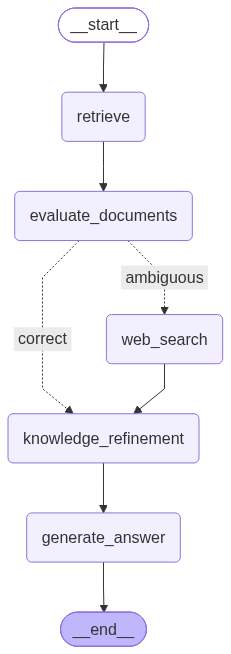

In [57]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Could not reach online Mermaid service. Graph ASCII representation:")
    print(graph.get_graph().draw_ascii())


---
## Part 12: Run Test Cases



In [58]:
initial_state = {
    "question": "What is gradient descent?",
    "documents": [],
    "web_documents": [],
    "scores": [],
    "action": "",
    "evaluation": "",
    "refined_documents": [],
    "answer": ""
}

result = graph.invoke(initial_state)

print("\n" + "="*60)
print(f"Action taken: {result.get('action')}")
print(f"Relevance scores: {result.get('scores')}")
print("="*60)
print(f"\nAnswer:\n{result.get('answer')}")


[evaluate_documents] Scores: [-1.0, -1.0, -1.0, -1.0] -> Action: 'incorrect'
[web_search] Querying Tavily for: 'What is gradient descent?'...

Action taken: incorrect
Relevance scores: [-1.0, -1.0, -1.0, -1.0]

Answer:
**Gradient descent** is an iterative optimization algorithm that finds the minimum of a differentiable cost (or loss) function. In machine learning it repeatedly adjusts model parameters (weights and biases) in the direction of the steepest descent of the function’s gradient until the error between predicted and actual outputs is minimized. The update rule for each parameter \( \theta \) is  

\[
\theta \leftarrow \theta - \alpha \frac{\partial J(\theta)}{\partial \theta},
\]

where \( \alpha \) is the learning rate and \( J(\theta) \) is the cost function. Gradient descent comes in three main flavors: batch, stochastic, and mini‑batch, each differing in how many training examples are used to compute the gradient at each update. The algorithm continues until the cost cha

In [59]:
initial_state_2 = {
    "question": "What is retrieval augmented generation?",
    "documents": [],
    "web_documents": [],
    "scores": [],
    "action": "",
    "evaluation": "",
    "refined_documents": [],
    "answer": ""
}

result_2 = graph.invoke(initial_state_2)

print("\n" + "="*60)
print(f"Action taken: {result_2.get('action')}")
print(f"Relevance scores: {result_2.get('scores')}")
print("="*60)
print(f"\nAnswer:\n{result_2.get('answer')}")


[evaluate_documents] Scores: [-0.5, -0.5, -0.5, 0.5] -> Action: 'ambiguous'
[web_search] Querying Tavily for: 'What is retrieval augmented generation?'...

Action taken: ambiguous
Relevance scores: [-0.5, -0.5, -0.5, 0.5]

Answer:
**Retrieval‑augmented generation (RAG)** is a method that improves large language models by adding a retrieval step before the model generates a response. The workflow is:

1. **Document preparation** – Text is divided into chunks, encoded into embeddings, and stored in a vector database.  
2. **Retrieval** – For a user’s query, a retriever model finds the most relevant documents or passages by matching the query’s embedding with those in the database.  
3. **Prompt augmentation** – The retrieved passages are inserted into the prompt (often through prompt engineering or “prompt stuffing”) and fed to the LLM.  
4. **Generation** – The LLM produces an answer that blends its internal knowledge with the retrieved context, usually citing the sources.

**Key benefi